# Estrus classification feature volcano plot

This plot compares feature direction (left/right) with individual predictive signal (vertical position). For the saved logistic model, horizontal position is the standardized coefficient: positive values increase the estrus probability and negative values increase the non-estrus probability. The vertical axis is a descriptive transform of individual average precision, not an inferential p-value.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib

from estrus.data import KEYS, load_labels
from estrus.features import assemble_features

ROOT = Path.cwd().resolve().parent
if not (ROOT / "pyproject.toml").exists():
    ROOT = Path.cwd().resolve()

WORKSPACE = ROOT / "data" / "outputs" / "notebook_features"
features, diagnostics = assemble_features(ROOT, WORKSPACE, baseline_only=False)
labels = load_labels()
frame = features.merge(labels.dropna(subset=["is_estrus"]), on=KEYS, how="inner", validate="one_to_one")
feature_columns = [column for column in features.columns if column not in KEYS]

result_dirs = sorted((ROOT / "Model Building" / "results").glob("*/"), key=lambda path: path.stat().st_mtime)
model_output = result_dirs[-1]
summary = pd.read_csv(model_output / "feature_summary.csv")
print(f"Features: {len(feature_columns)}")
print(f"Using model result: {model_output.name}")
summary.head()


[Matthew: accepted] 4 features
[Vivian: accepted] 6 features
[Brandon: missing] No export yet; skipped.
[Alisha: accepted] 18 features
Feature inputs: 28 contributor features only; reference features excluded.
Features: 28
Using model result: notebook-run-20261113T231216701940Z


,feature,name,owner,individual_ap,importance_ap_drop,used,status
0,alisha__dtw_shift_whole_temp,dtw_shift_whole_temp,Alisha,0.977513,0.054733,True,Used
1,vivian__adj_range,adj_range,Vivian,0.619117,0.033811,True,Used
2,matthew__cbt_fraction_above_37_2_h6_12,cbt_fraction_above_37_2_h6_12,Matthew,0.928517,0.017382,True,Used
3,alisha__dtw_shift_seg5_act,dtw_shift_seg5_act,Alisha,0.433270,0.007320,True,Used
4,alisha__dtw_shift_seg3_temp,dtw_shift_seg3_temp,Alisha,0.564167,0.004198,True,Used


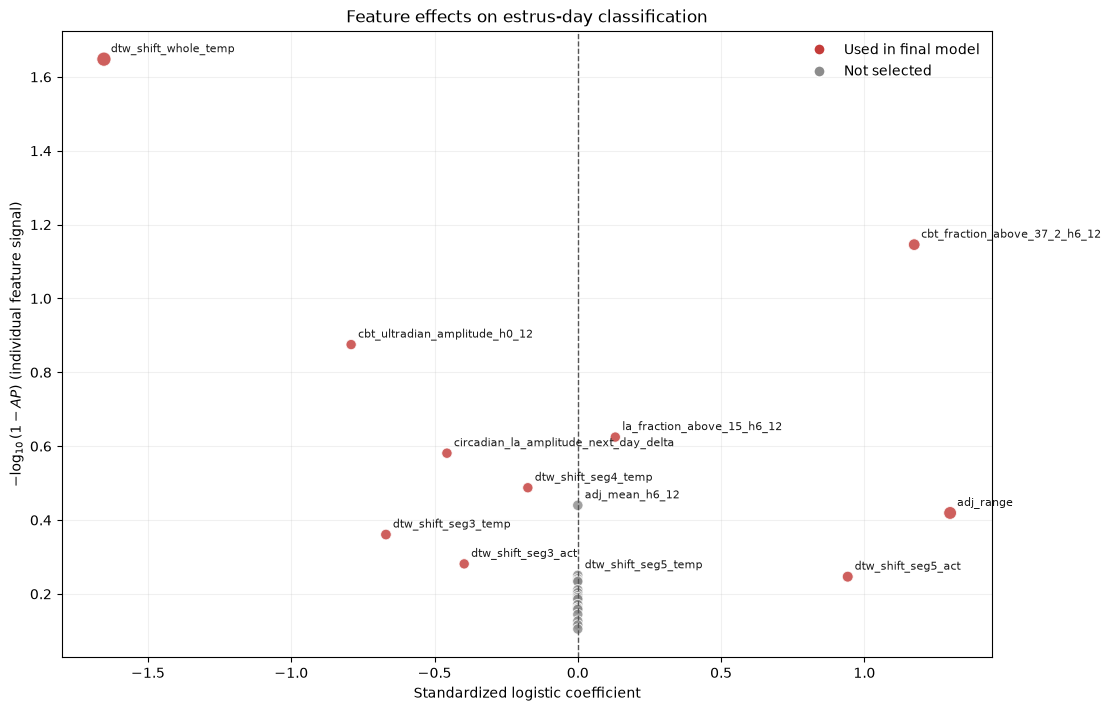

In [ ]:
plot = summary.copy()

# The coefficient axis is standardized for the logistic model, so coefficient sign
# gives feature direction and coefficient magnitude gives feature effect.
bundle = joblib.load(model_output / "model.joblib")
final_model = bundle["model"]
if hasattr(final_model, "calibrated_classifiers_"):
    fitted = final_model.calibrated_classifiers_[0].estimator
else:
    fitted = final_model

coefficients = None
if "model" in fitted.named_steps and hasattr(fitted.named_steps["model"], "coef_"):
    variance_support = fitted.named_steps["variance"].get_support()
    names = np.asarray(bundle["feature_columns"])[variance_support]
    selector = fitted.named_steps["select"]
    if selector != "passthrough":
        names = names[selector.get_support()]
    coefficients = pd.Series(fitted.named_steps["model"].coef_[0], index=names)

if coefficients is None:
    y = frame["is_estrus"].astype(int)
    directions = {}
    for feature in plot["feature"]:
        estrus = frame.loc[y.eq(1), feature].mean()
        non_estrus = frame.loc[y.eq(0), feature].mean()
        pooled_std = frame[feature].std()
        directions[feature] = (estrus - non_estrus) / pooled_std if pooled_std else 0.0
    plot["effect"] = plot["feature"].map(directions)
    direction_label = "Estrus-minus-non-estrus standardized mean difference"
else:
    plot["effect"] = plot["feature"].map(coefficients).fillna(0.0)
    direction_label = "Standardized logistic coefficient"

# Transform individual AP into a volcano-style vertical axis. It is descriptive:
# 0.0 is no gain beyond the null baseline; larger values mean stronger AP signal.
plot["signal"] = -np.log10(np.maximum(1.0 - plot["individual_ap"].clip(lower=0.0, upper=.999999), 1e-6))

fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
colors = plot["used"].map({True: "#c43c39", False: "#8c8c8c"})
sizes = 55 + 900 * np.maximum(plot["importance_ap_drop"], 0.0)
ax.scatter(plot["effect"], plot["signal"], s=sizes, c=colors, alpha=.82,
           edgecolors="white", linewidths=.7)
ax.axvline(0, color="#555555", lw=1, linestyle="--")

for row in plot.nlargest(12, "individual_ap").itertuples():
    ax.annotate(row.name, (row.effect, row.signal), xytext=(5, 5),
                textcoords="offset points", fontsize=8, alpha=.9)

ax.set_xlabel(direction_label)
ax.set_ylabel("$-\\log_{10}(1 - AP)$ (individual feature signal)")
ax.set_title("Feature effects on estrus-day classification")
ax.grid(axis="both", alpha=.18)
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#c43c39", markersize=8, label="Used in final model"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#8c8c8c", markersize=8, label="Not selected"),
], frameon=False)

# output_path = ROOT / "Brandon Feature Engineering" / "estrus_feature_volcano.png"
# fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
#print(f"Saved: {output_path}")

# X-axis: Shows the magnitude and direction of change. Positive values point to increases (upregulation), negative values point to 
# decreases (downregulation), and 0 means no change. Positive value means feature's mean is higher in estrus days than non-estrus days, 
# negative value means feature's mean is lower in estrus days than non-estrus days, and 0 means no effect on classification.
# X AXIS CALCULATION = log(MEAN IN CLASS 1 / MEAN IN CLASS 0) = log(MEAN IN ESTRUS / MEAN IN NON-ESTRUS)
# Y-axis: Shows statistical significance. Higher points represent smaller p-values and stronger statistical evidence.